In [7]:
%pip install matplotlib seaborn pandas numpy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Manufacturing Downtime Analysis - Ready!")

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/9.5 MB 3.3 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.5 MB 3.2 MB/s eta 0:00:03
   ----------- ---------------------------- 2.6/9.5 MB 3.3 MB/s eta 0:00:03
   -------------- ------------------------- 3.4/9.5 MB 3.3 MB/s eta 0:00:02
   ----------------- ---------------------- 4.2/9.5 MB 3.3 MB/s eta 0:00:02
   ------------------- -------------------- 4.7/9.5 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 3.3 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.5 MB 3.3 MB/s eta 0:00:02
   ------------------------- -------------- 6.0/9.5 MB 3.0 MB/s eta 0:00:02
   ---------------------------- ----------- 6.8/9.5 MB 3.1 MB/s eta 0:00:01
   ---------------------------------- ----- 8.1/9.5 MB 3.2 MB/s eta 0:00:01
   ----------------

Matplotlib is building the font cache; this may take a moment.


Manufacturing Downtime Analysis - Ready!


In [8]:
from pathlib import Path

data_path = Path("Data")

files = [
    "dim_date.csv",
    "dim_shift.csv",
    "downtime_events.csv",
    "fact_machine_shift.csv",
    "machines.csv",
    "products.csv"
]

datasets = {}

for file in files:
    df = pd.read_csv(data_path / file)
    datasets[file] = df

    print(f"\n{'='*50}")
    print(f"File: {file}")
    print(f"Rows: {df.shape[0]}")
    print(f"Columns: {df.shape[1]}")
    print(f"Column Names: {df.columns.tolist()}")


File: dim_date.csv
Rows: 123
Columns: 10
Column Names: ['Date', 'Year', 'Month_Num', 'Month_Name', 'Year_Month', 'Week_Num', 'Day_Of_Week_Num', 'Day_Name', 'Shifts_Planned', 'Is_Working_Day']

File: dim_shift.csv
Rows: 3
Columns: 6
Column Names: ['shift', 'shift_name', 'shift_order', 'start_hour', 'end_hour', 'shift_hours']

File: downtime_events.csv
Rows: 3240
Columns: 15
Column Names: ['event_id', 'slot_key', 'machine_id', 'event_date', 'shift', 'Start_Date', 'Start_Time', 'End_Date', 'End_Time', 'Start_Hour', 'Duration_Min', 'reason_code', 'Downtime_Type', 'operator_note', 'Time_Swapped']

File: fact_machine_shift.csv
Rows: 2016
Columns: 23
Column Names: ['log_id', 'slot_key', 'prod_date', 'shift', 'machine_id', 'work_order', 'product_id', 'planned_minutes', 'total_units', 'units_imputed', 'Downtime_Events', 'Downtime_Min', 'Planned_Downtime_Min', 'Unplanned_Downtime_Min', 'Unclassified_Downtime_Min', 'Rejected_Units', 'Invalid_Reject_Count', 'primary_defect', 'Run_Time_Min', 'Idea

In [9]:
from pathlib import Path

print("Current Working Directory:")
print(Path.cwd())

print("\nFiles in Current Directory:")
print(list(Path.cwd().iterdir()))

Current Working Directory:
c:\Users\HP\Desktop\test

Files in Current Directory:
[WindowsPath('c:/Users/HP/Desktop/test/Data'), WindowsPath('c:/Users/HP/Desktop/test/manufacturing_analysis.ipynb')]


In [10]:
from pathlib import Path

print(Path.cwd())
print(list(Path.cwd().iterdir()))

c:\Users\HP\Desktop\test
[WindowsPath('c:/Users/HP/Desktop/test/Data'), WindowsPath('c:/Users/HP/Desktop/test/manufacturing_analysis.ipynb')]


In [11]:
from pathlib import Path

data_path = Path("Data")

print("Data folder exists:", data_path.exists())

print("\nFiles inside Data folder:")

for file in data_path.iterdir():
    print(file.name)

Data folder exists: True

Files inside Data folder:
dim_date.csv
dim_shift.csv
downtime_events.csv
fact_machine_shift.csv
machines.csv
products.csv


In [12]:
import pandas as pd
from pathlib import Path

data_path = Path("Data")

files = [
    "dim_date.csv",
    "dim_shift.csv",
    "downtime_events.csv",
    "fact_machine_shift.csv",
    "machines.csv",
    "products.csv"
]

datasets = {}

for file in files:
    df = pd.read_csv(data_path / file)
    datasets[file] = df

    print(f"{file}: {df.shape[0]} rows, {df.shape[1]} columns")
    print("Columns:", df.columns.tolist())
    print("-" * 60)

dim_date.csv: 123 rows, 10 columns
Columns: ['Date', 'Year', 'Month_Num', 'Month_Name', 'Year_Month', 'Week_Num', 'Day_Of_Week_Num', 'Day_Name', 'Shifts_Planned', 'Is_Working_Day']
------------------------------------------------------------
dim_shift.csv: 3 rows, 6 columns
Columns: ['shift', 'shift_name', 'shift_order', 'start_hour', 'end_hour', 'shift_hours']
------------------------------------------------------------
downtime_events.csv: 3240 rows, 15 columns
Columns: ['event_id', 'slot_key', 'machine_id', 'event_date', 'shift', 'Start_Date', 'Start_Time', 'End_Date', 'End_Time', 'Start_Hour', 'Duration_Min', 'reason_code', 'Downtime_Type', 'operator_note', 'Time_Swapped']
------------------------------------------------------------
fact_machine_shift.csv: 2016 rows, 23 columns
Columns: ['log_id', 'slot_key', 'prod_date', 'shift', 'machine_id', 'work_order', 'product_id', 'planned_minutes', 'total_units', 'units_imputed', 'Downtime_Events', 'Downtime_Min', 'Planned_Downtime_Min', '

In [13]:
for name, df in datasets.items():

    print(f"\n{'='*60}")
    print(f"DATASET: {name}")
    print(f"{'='*60}")

    print("\n1. Missing Values:")
    print(df.isnull().sum())

    print("\n2. Duplicate Rows:")
    print(df.duplicated().sum())

    print("\n3. Data Types:")
    print(df.dtypes)


DATASET: dim_date.csv

1. Missing Values:
Date               0
Year               0
Month_Num          0
Month_Name         0
Year_Month         0
Week_Num           0
Day_Of_Week_Num    0
Day_Name           0
Shifts_Planned     0
Is_Working_Day     0
dtype: int64

2. Duplicate Rows:
0

3. Data Types:
Date                 str
Year               int64
Month_Num          int64
Month_Name           str
Year_Month           str
Week_Num           int64
Day_Of_Week_Num    int64
Day_Name             str
Shifts_Planned     int64
Is_Working_Day     int64
dtype: object

DATASET: dim_shift.csv

1. Missing Values:
shift          0
shift_name     0
shift_order    0
start_hour     0
end_hour       0
shift_hours    0
dtype: int64

2. Duplicate Rows:
0

3. Data Types:
shift            str
shift_name       str
shift_order    int64
start_hour     int64
end_hour       int64
shift_hours    int64
dtype: object

DATASET: downtime_events.csv

1. Missing Values:
event_id         0
slot_key         0
machine

In [14]:
quality_report = []

for name, df in datasets.items():

    quality_report.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": df.isnull().sum().sum(),
        "Duplicate Rows": df.duplicated().sum(),
        "Missing Columns": (df.isnull().sum() > 0).sum()
    })

quality_df = pd.DataFrame(quality_report)

display(quality_df)

,Dataset,Rows,Columns,Missing Values,Duplicate Rows,Missing Columns
0,dim_date.csv,123,10,0,0,0
1,dim_shift.csv,3,6,0,0,0
2,downtime_events.csv,3240,15,0,0,0
3,fact_machine_shift.csv,2016,23,25,0,4
4,machines.csv,9,5,0,0,0
5,products.csv,6,4,0,0,0


In [15]:
df = datasets["fact_machine_shift.csv"]

missing_report = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

display(missing_report[missing_report["Missing Count"] > 0])

,Missing Count,Missing Percentage
Rejected_Units,8,0.40
primary_defect,1,0.05
Good_Units,8,0.40
Scrap_Cost_USD,8,0.40


In [16]:
df = datasets["fact_machine_shift.csv"]

columns_to_check = [
    "Rejected_Units",
    "primary_defect",
    "Good_Units",
    "Scrap_Cost_USD"
]

missing_rows = df[df[columns_to_check].isnull().any(axis=1)]

print("Total rows with missing values:", len(missing_rows))

display(
    missing_rows[
        ["log_id", "machine_id", "prod_date", "total_units"] 
        + columns_to_check
    ]
)

Total rows with missing values: 9


,log_id,machine_id,prod_date,total_units,Rejected_Units,primary_defect,Good_Units,Scrap_Cost_USD
98,100,CNC-01,2026-07-06,521,NaN,Porosity,NaN,NaN
217,220,CNC-05,2026-07-10,655,NaN,Burr / Sharp Edge,NaN,NaN
694,707,ASM-07,2026-08-01,151,0.0,NaN,151.0,0.0
880,887,ASM-08,2026-08-10,253,NaN,Burr / Sharp Edge,NaN,NaN
884,891,ASM-09,2026-08-10,357,NaN,Burr / Sharp Edge,NaN,NaN
949,959,CNC-05,2026-08-13,599,NaN,Porosity,NaN,NaN
983,998,ASM-09,2026-08-14,266,NaN,Assembly Misfit,NaN,NaN
1398,1407,CNC-01,2026-09-03,580,NaN,Surface Finish,NaN,NaN
1447,1462,CNC-02,2026-09-05,430,NaN,Surface Finish,NaN,NaN


In [17]:
# Create a copy to preserve original data
df_clean = datasets["fact_machine_shift.csv"].copy()

# Fill missing defect only when rejected units = 0
condition = (
    df_clean["primary_defect"].isna()
    & (df_clean["Rejected_Units"] == 0)
)

df_clean.loc[condition, "primary_defect"] = "No Defect"

print("Remaining Missing Values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

Remaining Missing Values:
Rejected_Units    8
Good_Units        8
Scrap_Cost_USD    8
dtype: int64


In [18]:
print(df_clean.columns.tolist())

['log_id', 'slot_key', 'prod_date', 'shift', 'machine_id', 'work_order', 'product_id', 'planned_minutes', 'total_units', 'units_imputed', 'Downtime_Events', 'Downtime_Min', 'Planned_Downtime_Min', 'Unplanned_Downtime_Min', 'Unclassified_Downtime_Min', 'Rejected_Units', 'Invalid_Reject_Count', 'primary_defect', 'Run_Time_Min', 'Ideal_Units', 'Quality_Basis_Units', 'Good_Units', 'Scrap_Cost_USD']


In [19]:
# Investigate available columns and missing quality records

print("All available columns:\n")

for col in df_clean.columns:
    print(col)

print("\n" + "=" * 60)

print("Missing quality records:\n")

missing_quality = df_clean[
    df_clean["Rejected_Units"].isna()
].copy()

display(missing_quality.T)

All available columns:

log_id
slot_key
prod_date
shift
machine_id
work_order
product_id
planned_minutes
total_units
units_imputed
Downtime_Events
Downtime_Min
Planned_Downtime_Min
Unplanned_Downtime_Min
Unclassified_Downtime_Min
Rejected_Units
Invalid_Reject_Count
primary_defect
Run_Time_Min
Ideal_Units
Quality_Basis_Units
Good_Units
Scrap_Cost_USD

Missing quality records:



,98,217,880,884,949,983,1398,1447
log_id,100,220,887,891,959,998,1407,1462
slot_key,CNC-01|20260706|A,CNC-05|20260710|A,ASM-08|20260810|B,ASM-09|20260810|C,CNC-05|20260813|B,ASM-09|20260814|B,CNC-01|20260903|C,CNC-02|20260905|B
prod_date,2026-07-06,2026-07-10,2026-08-10,2026-08-10,2026-08-13,2026-08-14,2026-09-03,2026-09-05
shift,A,A,B,C,B,B,C,B
machine_id,CNC-01,CNC-05,ASM-08,ASM-09,CNC-05,ASM-09,CNC-01,CNC-02
work_order,WO-50035,WO-50078,WO-50315,WO-50317,WO-50335,WO-50346,WO-50488,WO-50511
product_id,P-101,P-104,P-106,P-106,P-104,P-106,P-102,P-102
planned_minutes,450,450,450,450,450,450,450,450
total_units,521,655,253,357,599,266,580,430
units_imputed,0,0,0,0,0,0,0,0


In [20]:
# Create a quality validation flag

df_clean["Quality_Data_Valid"] = (
    df_clean["Rejected_Units"].notna()
    & df_clean["Good_Units"].notna()
    & df_clean["Scrap_Cost_USD"].notna()
    & (df_clean["Invalid_Reject_Count"] == 0)
    & (df_clean["Quality_Basis_Units"] > 0)
)

print("Quality Data Validation Results:")

print(df_clean["Quality_Data_Valid"].value_counts())

print("\nRemaining Missing Values:")

print(
    df_clean.isnull().sum()[
        df_clean.isnull().sum() > 0
    ]
)

Quality Data Validation Results:
Quality_Data_Valid
True     2008
False       8
Name: count, dtype: int64

Remaining Missing Values:
Rejected_Units    8
Good_Units        8
Scrap_Cost_USD    8
dtype: int64


In [21]:
# Convert production date to datetime
df_clean["prod_date"] = pd.to_datetime(
    df_clean["prod_date"],
    errors="coerce"
)

# Create copies of the other datasets
cleaned_datasets = {
    name: df.copy()
    for name, df in datasets.items()
}

# Replace production table with our cleaned version
cleaned_datasets["fact_machine_shift.csv"] = df_clean

# Convert date dimension
cleaned_datasets["dim_date.csv"]["Date"] = pd.to_datetime(
    cleaned_datasets["dim_date.csv"]["Date"],
    errors="coerce"
)

# Convert downtime event date
cleaned_datasets["downtime_events.csv"]["event_date"] = pd.to_datetime(
    cleaned_datasets["downtime_events.csv"]["event_date"],
    errors="coerce"
)

print("Date Conversion Results:\n")

for name, column in [
    ("fact_machine_shift.csv", "prod_date"),
    ("dim_date.csv", "Date"),
    ("downtime_events.csv", "event_date")
]:
    df_check = cleaned_datasets[name]

    print(f"{name}")
    print("Data Type:", df_check[column].dtype)
    print("Invalid Dates:", df_check[column].isna().sum())
    print("-" * 40)

Date Conversion Results:

fact_machine_shift.csv
Data Type: datetime64[us]
Invalid Dates: 0
----------------------------------------
dim_date.csv
Data Type: datetime64[us]
Invalid Dates: 0
----------------------------------------
downtime_events.csv
Data Type: datetime64[us]
Invalid Dates: 0
----------------------------------------


In [22]:
df = cleaned_datasets["fact_machine_shift.csv"]

validation_report = {
    "Negative Total Units":
        (df["total_units"] < 0).sum(),

    "Negative Planned Minutes":
        (df["planned_minutes"] < 0).sum(),

    "Negative Downtime":
        (df["Downtime_Min"] < 0).sum(),

    "Negative Run Time":
        (df["Run_Time_Min"] < 0).sum(),

    "Downtime Exceeds Planned Time":
        (df["Downtime_Min"] > df["planned_minutes"]).sum(),

    "Run Time + Downtime Mismatch":
        (
            (df["Run_Time_Min"] + df["Downtime_Min"])
            != df["planned_minutes"]
        ).sum(),

    "Good + Rejected Units Mismatch":
        (
            df["Quality_Data_Valid"]
            & (
                (df["Good_Units"] + df["Rejected_Units"])
                != df["total_units"]
            )
        ).sum()
}

validation_df = pd.DataFrame(
    validation_report.items(),
    columns=["Validation Rule", "Issues Found"]
)

display(validation_df)

,Validation Rule,Issues Found
0,Negative Total Units,0
1,Negative Planned Minutes,0
2,Negative Downtime,0
3,Negative Run Time,0
4,Downtime Exceeds Planned Time,0
5,Run Time + Downtime Mismatch,0
6,Good + Rejected Units Mismatch,0


In [23]:
from pathlib import Path

# Create output folder
output_path = Path("Cleaned_Data")
output_path.mkdir(exist_ok=True)

# Export cleaned datasets
for name, df in cleaned_datasets.items():

    output_file = output_path / name

    df.to_csv(output_file, index=False)

    print(f"Exported: {output_file}")

print("\nAll cleaned datasets exported successfully!")

Exported: Cleaned_Data\dim_date.csv
Exported: Cleaned_Data\dim_shift.csv
Exported: Cleaned_Data\downtime_events.csv
Exported: Cleaned_Data\fact_machine_shift.csv
Exported: Cleaned_Data\machines.csv
Exported: Cleaned_Data\products.csv

All cleaned datasets exported successfully!


In [24]:
import pandas as pd

# Read exported dataset
exported_df = pd.read_csv(
    "Cleaned_Data/fact_machine_shift.csv"
)

# Check cleaning results
print("Total Rows:", len(exported_df))

print("\nQuality Validation Column:")
print("Quality_Data_Valid" in exported_df.columns)

print("\nMissing Values:")
print(
    exported_df[
        ["Rejected_Units", "Good_Units",
         "Scrap_Cost_USD", "primary_defect"]
    ].isnull().sum()
)

print("\nQuality Status:")
if "Quality_Data_Valid" in exported_df.columns:
    print(exported_df["Quality_Data_Valid"].value_counts())

Total Rows: 2016

Quality Validation Column:
True

Missing Values:
Rejected_Units    8
Good_Units        8
Scrap_Cost_USD    8
primary_defect    0
dtype: int64

Quality Status:
Quality_Data_Valid
True     2008
False       8
Name: count, dtype: int64


In [25]:
import pandas as pd

# Load cleaned datasets
fact = pd.read_csv("Cleaned_Data/fact_machine_shift.csv")
events = pd.read_csv("Cleaned_Data/downtime_events.csv")

# Calculate downtime KPIs
total_downtime_min = fact["Downtime_Min"].sum()

total_downtime_hours = total_downtime_min / 60

total_downtime_events = len(events)

avg_downtime = fact["Downtime_Min"].mean()

# Display results
print("MANUFACTURING DOWNTIME KPIs")
print("-" * 40)

print(f"Total Downtime (Minutes): {total_downtime_min:,.0f}")

print(f"Total Downtime (Hours): {total_downtime_hours:,.2f}")

print(f"Total Downtime Events: {total_downtime_events:,}")

print(f"Average Downtime per Machine-Shift: {avg_downtime:.2f} minutes")


MANUFACTURING DOWNTIME KPIs
----------------------------------------
Total Downtime (Minutes): 131,004
Total Downtime (Hours): 2,183.40
Total Downtime Events: 3,240
Average Downtime per Machine-Shift: 64.98 minutes


In [26]:
# Downtime Analysis by Machine

machine_analysis = (
    fact.groupby("machine_id")
    .agg(
        Total_Downtime_Min=("Downtime_Min", "sum"),
        Average_Downtime_Min=("Downtime_Min", "mean"),
        Total_Records=("log_id", "count")
    )
    .reset_index()
)

# Calculate downtime percentage
machine_analysis["Downtime_Percentage"] = (
    machine_analysis["Total_Downtime_Min"]
    / total_downtime_min
    * 100
).round(2)

# Sort machines by downtime
machine_analysis = machine_analysis.sort_values(
    by="Total_Downtime_Min",
    ascending=False
)

display(machine_analysis)


,machine_id,Total_Downtime_Min,Average_Downtime_Min,Total_Records,Downtime_Percentage
1,ASM-08,19195,85.691964,224,14.65
7,CNC-05,18549,82.808036,224,14.16
0,ASM-07,18531,82.727679,224,14.15
2,ASM-09,18348,81.910714,224,14.01
5,CNC-03,12131,54.156250,224,9.26
4,CNC-02,11376,50.785714,224,8.68
6,CNC-04,11296,50.428571,224,8.62
3,CNC-01,11150,49.776786,224,8.51
8,CNC-06,10428,46.553571,224,7.96


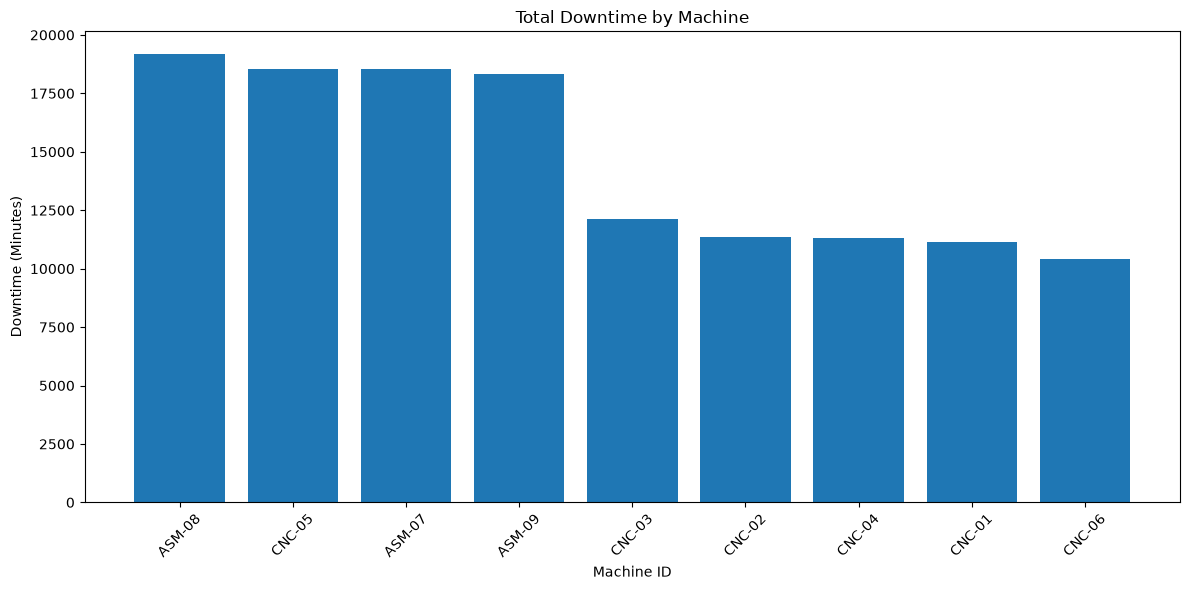

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.bar(
    machine_analysis["machine_id"],
    machine_analysis["Total_Downtime_Min"]
)

plt.title("Total Downtime by Machine")
plt.xlabel("Machine ID")
plt.ylabel("Downtime (Minutes)")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [28]:
# Calculate machine downtime rate

machine_performance = (
    fact.groupby("machine_id")
    .agg(
        Total_Downtime_Min=("Downtime_Min", "sum"),
        Total_Planned_Min=("planned_minutes", "sum"),
        Total_Shifts=("log_id", "count")
    )
    .reset_index()
)

# Calculate downtime rate
machine_performance["Downtime_Rate_%"] = (
    machine_performance["Total_Downtime_Min"]
    / machine_performance["Total_Planned_Min"]
    * 100
).round(2)

# Sort by highest downtime rate
machine_performance = machine_performance.sort_values(
    by="Downtime_Rate_%",
    ascending=False
)

display(machine_performance)

,machine_id,Total_Downtime_Min,Total_Planned_Min,Total_Shifts,Downtime_Rate_%
1,ASM-08,19195,100800,224,19.04
7,CNC-05,18549,100800,224,18.40
0,ASM-07,18531,100800,224,18.38
2,ASM-09,18348,100800,224,18.20
5,CNC-03,12131,100800,224,12.03
4,CNC-02,11376,100800,224,11.29
6,CNC-04,11296,100800,224,11.21
3,CNC-01,11150,100800,224,11.06
8,CNC-06,10428,100800,224,10.35


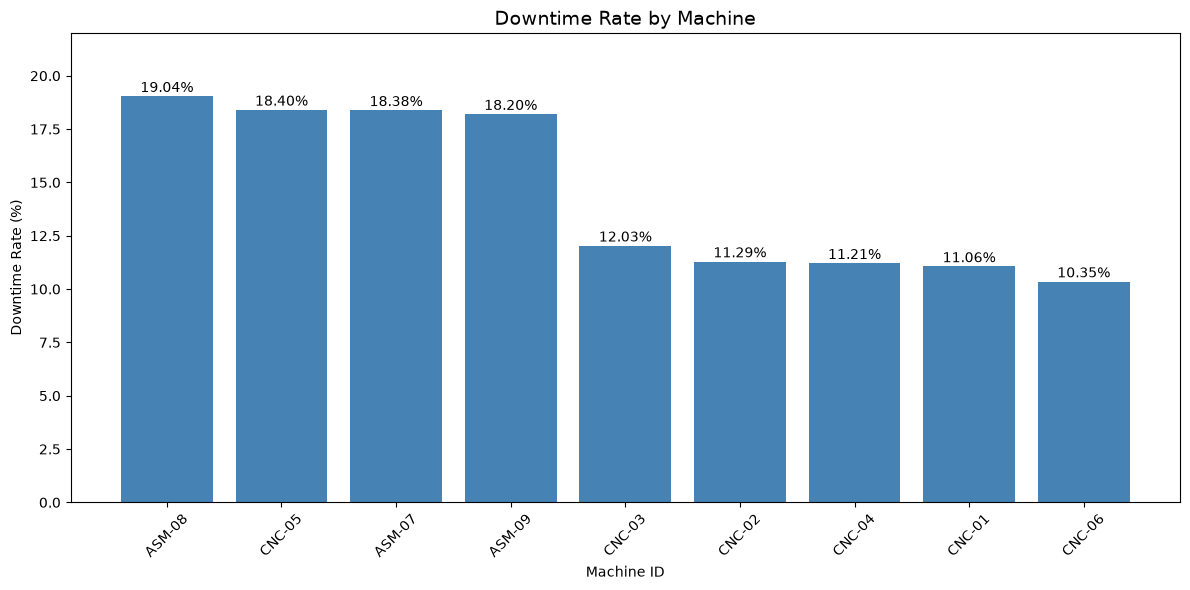

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

bars = plt.bar(
    machine_performance["machine_id"],
    machine_performance["Downtime_Rate_%"],
    color="steelblue"
)

plt.title("Downtime Rate by Machine", fontsize=14)
plt.xlabel("Machine ID")
plt.ylabel("Downtime Rate (%)")

plt.xticks(rotation=45)

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.2f}%",
        ha="center"
    )

plt.ylim(0, 22)
plt.tight_layout()
plt.show()

In [30]:
# Step 19: Downtime Analysis by Shift

# Group data by shift
shift_performance = fact.groupby("shift").agg(
    Total_Downtime_Min=("Downtime_Min", "sum"),
    Total_Planned_Min=("planned_minutes", "sum"),
    Total_Shifts=("log_id", "count")
).reset_index()

# Calculate downtime rate
shift_performance["Downtime_Rate_%"] = (
    shift_performance["Total_Downtime_Min"]
    / shift_performance["Total_Planned_Min"]
    * 100
).round(2)

# Sort by highest downtime rate
shift_performance = shift_performance.sort_values(
    by="Downtime_Rate_%",
    ascending=False
)

display(shift_performance)

,shift,Total_Downtime_Min,Total_Planned_Min,Total_Shifts,Downtime_Rate_%
2,C,43369,267300,594,16.22
1,B,45595,319950,711,14.25
0,A,42040,319950,711,13.14


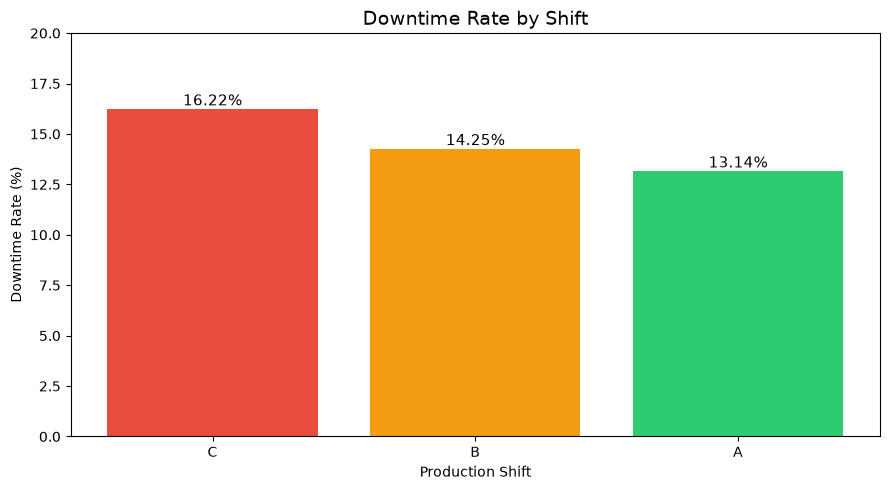

In [31]:
# Step 20: Downtime Rate by Shift Visualization

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

bars = plt.bar(
    shift_performance["shift"],
    shift_performance["Downtime_Rate_%"],
    color=["#E74C3C", "#F39C12", "#2ECC71"]
)

plt.title("Downtime Rate by Shift", fontsize=14)
plt.xlabel("Production Shift")
plt.ylabel("Downtime Rate (%)")

# Add percentage labels
for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.2,
        f"{height:.2f}%",
        ha="center",
        fontsize=11
    )

plt.ylim(0, 20)
plt.tight_layout()
plt.show()

In [32]:
# Step 21: Explore Downtime Events

import pandas as pd

# Load downtime events
events = pd.read_csv("Cleaned_Data/downtime_events.csv")

print("Dataset Shape:")
print(events.shape)

print("\nColumn Names:")
print(events.columns.tolist())

print("\nFirst 5 Rows:")
display(events.head())

print("\nData Types:")
print(events.dtypes)

print("\nMissing Values:")
print(events.isnull().sum())

Dataset Shape:
(3240, 15)

Column Names:
['event_id', 'slot_key', 'machine_id', 'event_date', 'shift', 'Start_Date', 'Start_Time', 'End_Date', 'End_Time', 'Start_Hour', 'Duration_Min', 'reason_code', 'Downtime_Type', 'operator_note', 'Time_Swapped']

First 5 Rows:


,event_id,slot_key,machine_id,event_date,shift,Start_Date,Start_Time,End_Date,End_Time,Start_Hour,Duration_Min,reason_code,Downtime_Type,operator_note,Time_Swapped
0,1,CNC-01|20260701|A,CNC-01,2026-07-01,A,2026-07-01,06:25:00,2026-07-01,06:58:00,6,33,Unknown,Unclassified,waiting on supervisor,0
1,2,CNC-01|20260701|A,CNC-01,2026-07-01,A,2026-07-01,07:38:00,2026-07-01,08:16:00,7,38,Quality Hold,Unplanned,No note,0
2,3,CNC-01|20260701|B,CNC-01,2026-07-01,B,2026-07-01,14:34:00,2026-07-01,15:31:00,14,57,Mechanical Breakdown,Unplanned,No note,0
3,4,CNC-01|20260701|C,CNC-01,2026-07-01,C,2026-07-01,22:14:00,2026-07-01,23:15:00,22,61,Material Shortage,Unplanned,waiting on supervisor,0
4,5,CNC-01|20260701|C,CNC-01,2026-07-01,C,2026-07-02,00:11:00,2026-07-02,00:39:00,0,28,Changeover / Setup,Planned,waiting on supervisor,0



Data Types:
event_id         int64
slot_key           str
machine_id         str
event_date         str
shift              str
Start_Date         str
Start_Time         str
End_Date           str
End_Time           str
Start_Hour       int64
Duration_Min     int64
reason_code        str
Downtime_Type      str
operator_note      str
Time_Swapped     int64
dtype: object

Missing Values:
event_id         0
slot_key         0
machine_id       0
event_date       0
shift            0
Start_Date       0
Start_Time       0
End_Date         0
End_Time         0
Start_Hour       0
Duration_Min     0
reason_code      0
Downtime_Type    0
operator_note    0
Time_Swapped     0
dtype: int64


In [33]:
# Step 22: Validate Downtime Events

# Total downtime from machine-shift fact table
fact_downtime = fact["Downtime_Min"].sum()

# Total downtime from individual events
events_downtime = events["Duration_Min"].sum()

# Calculate difference
difference = events_downtime - fact_downtime

print("DOWNTIME DATA VALIDATION")
print("-" * 45)

print(f"Fact Table Downtime: {fact_downtime:,.0f} minutes")
print(f"Events Table Downtime: {events_downtime:,.0f} minutes")
print(f"Difference: {difference:,.0f} minutes")

print("\nTotal Events:", len(events))
print("Missing Values:", events.isnull().sum().sum())
print("Duplicate Event IDs:", events["event_id"].duplicated().sum())

if difference == 0:
    print("\nValidation Status: PASSED")
else:
    print("\nValidation Status: NEEDS INVESTIGATION")

DOWNTIME DATA VALIDATION
---------------------------------------------
Fact Table Downtime: 131,004 minutes
Events Table Downtime: 131,004 minutes
Difference: 0 minutes

Total Events: 3240
Missing Values: 0
Duplicate Event IDs: 0

Validation Status: PASSED


In [34]:
# Step 23: Downtime Reasons Analysis

# Group downtime events by reason
reason_analysis = (
    events.groupby("reason_code")
    .agg(
        Total_Downtime_Min=("Duration_Min", "sum"),
        Total_Events=("event_id", "count"),
        Avg_Downtime_Min=("Duration_Min", "mean")
    )
    .reset_index()
)

# Calculate contribution percentage
reason_analysis["Downtime_Contribution_%"] = (
    reason_analysis["Total_Downtime_Min"]
    / events["Duration_Min"].sum()
    * 100
).round(2)

# Round average downtime
reason_analysis["Avg_Downtime_Min"] = (
    reason_analysis["Avg_Downtime_Min"].round(2)
)

# Sort by highest downtime
reason_analysis = reason_analysis.sort_values(
    by="Total_Downtime_Min",
    ascending=False
).reset_index(drop=True)

print("DOWNTIME REASONS ANALYSIS")
print("-" * 50)

display(reason_analysis)

# Validate total downtime
print(
    "\nTotal Downtime:",
    reason_analysis["Total_Downtime_Min"].sum()
)

print(
    "Total Events:",
    reason_analysis["Total_Events"].sum()
)

print(
    "Total Contribution:",
    round(reason_analysis["Downtime_Contribution_%"].sum(), 2),
    "%"
)

DOWNTIME REASONS ANALYSIS
--------------------------------------------------


,reason_code,Total_Downtime_Min,Total_Events,Avg_Downtime_Min,Downtime_Contribution_%
0,Mechanical Breakdown,44087,752,58.63,33.65
1,Changeover / Setup,31021,736,42.15,23.68
2,Material Shortage,17105,401,42.66,13.06
3,Unknown,11237,270,41.62,8.58
4,Tool Change,9355,490,19.09,7.14
5,OTHER,7466,193,38.68,5.70
6,Quality Hold,6508,228,28.54,4.97
7,Operator Unavailable,4225,170,24.85,3.23



Total Downtime: 131004
Total Events: 3240
Total Contribution: 100.01 %


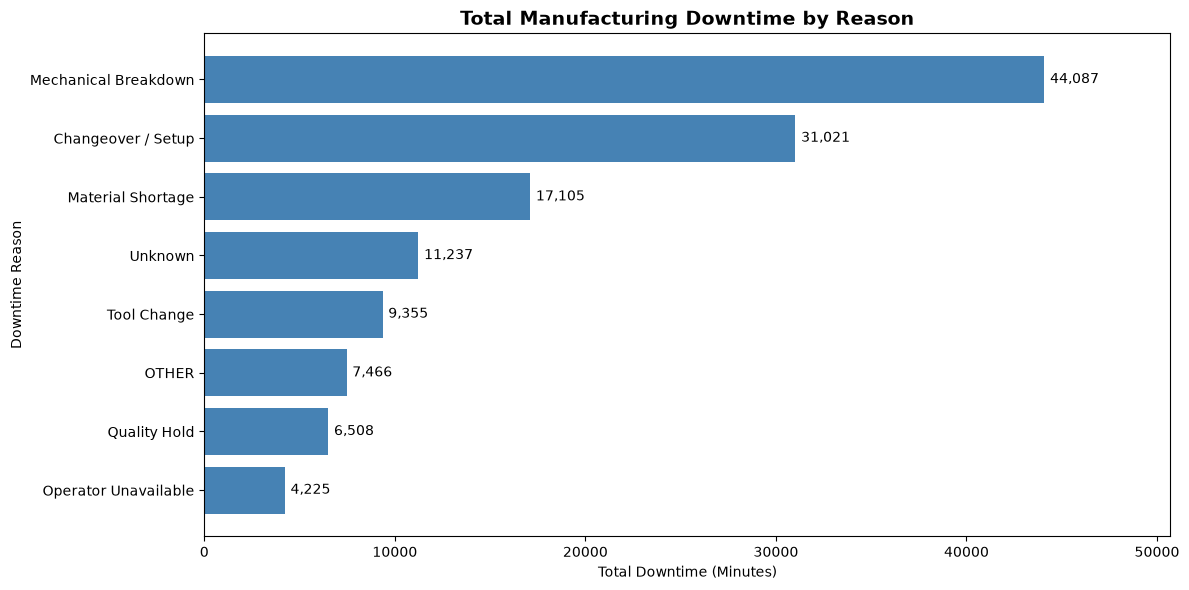

In [35]:
# Step 24: Downtime Reasons Visualization

import matplotlib.pyplot as plt

# Sort reasons for horizontal chart
reason_chart = reason_analysis.sort_values(
    by="Total_Downtime_Min",
    ascending=True
)

plt.figure(figsize=(12, 6))

bars = plt.barh(
    reason_chart["reason_code"],
    reason_chart["Total_Downtime_Min"],
    color="steelblue"
)

# Add downtime values
for bar in bars:
    width = bar.get_width()

    plt.text(
        width + 300,
        bar.get_y() + bar.get_height() / 2,
        f"{width:,.0f}",
        va="center",
        fontsize=10
    )

plt.title(
    "Total Manufacturing Downtime by Reason",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Total Downtime (Minutes)")
plt.ylabel("Downtime Reason")

plt.xlim(
    0,
    reason_chart["Total_Downtime_Min"].max() * 1.15
)

plt.tight_layout()
plt.show()


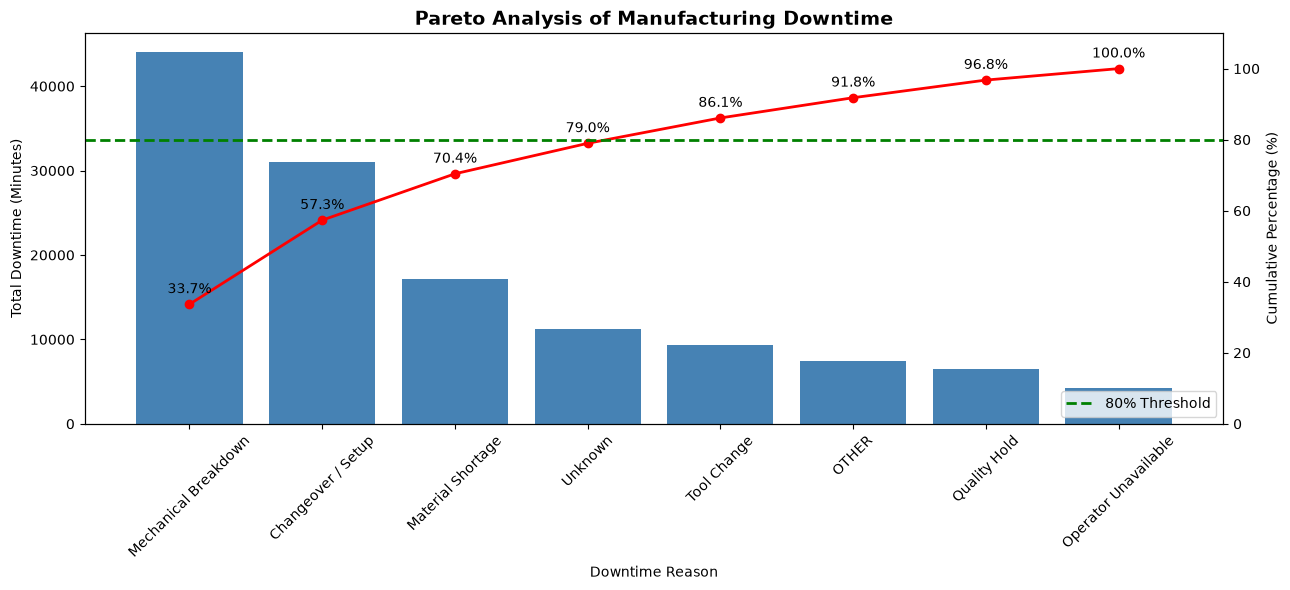

,reason_code,Total_Downtime_Min,Downtime_Contribution_%,Cumulative_Percentage
0,Mechanical Breakdown,44087,33.65,33.653171
1,Changeover / Setup,31021,23.68,57.332601
2,Material Shortage,17105,13.06,70.389454
3,Unknown,11237,8.58,78.967054
4,Tool Change,9355,7.14,86.108058
5,OTHER,7466,5.70,91.807120
6,Quality Hold,6508,4.97,96.774908
7,Operator Unavailable,4225,3.23,100.000000


In [36]:
# Step 25: Pareto Analysis

import pandas as pd
import matplotlib.pyplot as plt

# Sort downtime reasons
pareto_df = reason_analysis.sort_values(
    by="Total_Downtime_Min",
    ascending=False
).copy()

# Calculate cumulative percentage
pareto_df["Cumulative_Percentage"] = (
    pareto_df["Total_Downtime_Min"].cumsum()
    / pareto_df["Total_Downtime_Min"].sum()
    * 100
)

# Create Pareto chart
fig, ax1 = plt.subplots(figsize=(13, 6))

# Bar chart
ax1.bar(
    pareto_df["reason_code"],
    pareto_df["Total_Downtime_Min"],
    color="steelblue"
)

ax1.set_xlabel("Downtime Reason")
ax1.set_ylabel("Total Downtime (Minutes)")
ax1.tick_params(axis="x", rotation=45)

# Secondary axis
ax2 = ax1.twinx()

ax2.plot(
    pareto_df["reason_code"],
    pareto_df["Cumulative_Percentage"],
    color="red",
    marker="o",
    linewidth=2
)

ax2.set_ylabel("Cumulative Percentage (%)")
ax2.set_ylim(0, 110)

# 80% reference line
ax2.axhline(
    y=80,
    color="green",
    linestyle="--",
    linewidth=2,
    label="80% Threshold"
)

# Percentage labels
for i, value in enumerate(
    pareto_df["Cumulative_Percentage"]
):
    ax2.annotate(
        f"{value:.1f}%",
        (i, value),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center"
    )

ax2.legend(loc="lower right")

plt.title(
    "Pareto Analysis of Manufacturing Downtime",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

# Display Pareto table
display(
    pareto_df[
        [
            "reason_code",
            "Total_Downtime_Min",
            "Downtime_Contribution_%",
            "Cumulative_Percentage"
        ]
    ]
)

In [37]:
# Step 26: Planned vs Unplanned Downtime Analysis

import pandas as pd

# Load cleaned downtime events
events = pd.read_csv(
    "Cleaned_Data/downtime_events.csv"
)

# Group downtime by type
downtime_type_analysis = (
    events.groupby("Downtime_Type")
    .agg(
        Total_Downtime_Min=("Duration_Min", "sum"),
        Total_Events=("event_id", "count"),
        Avg_Downtime_Min=("Duration_Min", "mean")
    )
    .reset_index()
)

# Calculate contribution percentage
total_downtime = downtime_type_analysis[
    "Total_Downtime_Min"
].sum()

downtime_type_analysis["Downtime_Contribution_%"] = (
    downtime_type_analysis["Total_Downtime_Min"]
    / total_downtime
    * 100
).round(2)

# Round average downtime
downtime_type_analysis["Avg_Downtime_Min"] = (
    downtime_type_analysis["Avg_Downtime_Min"].round(2)
)

# Sort by highest downtime
downtime_type_analysis = downtime_type_analysis.sort_values(
    by="Total_Downtime_Min",
    ascending=False
)

print("PLANNED VS UNPLANNED DOWNTIME ANALYSIS")
print("-" * 50)

display(downtime_type_analysis)

# Validate total downtime
print("\nTotal Downtime:", total_downtime)

print(
    "Total Events:",
    downtime_type_analysis["Total_Events"].sum()
)

print(
    "Total Contribution:",
    round(
        downtime_type_analysis["Downtime_Contribution_%"].sum(),
        2
    ),
    "%"
)

PLANNED VS UNPLANNED DOWNTIME ANALYSIS
--------------------------------------------------


,Downtime_Type,Total_Downtime_Min,Total_Events,Avg_Downtime_Min,Downtime_Contribution_%
2,Unplanned,71925,1551,46.37,54.90
0,Planned,40376,1226,32.93,30.82
1,Unclassified,18703,463,40.40,14.28



Total Downtime: 131004
Total Events: 3240
Total Contribution: 100.0 %


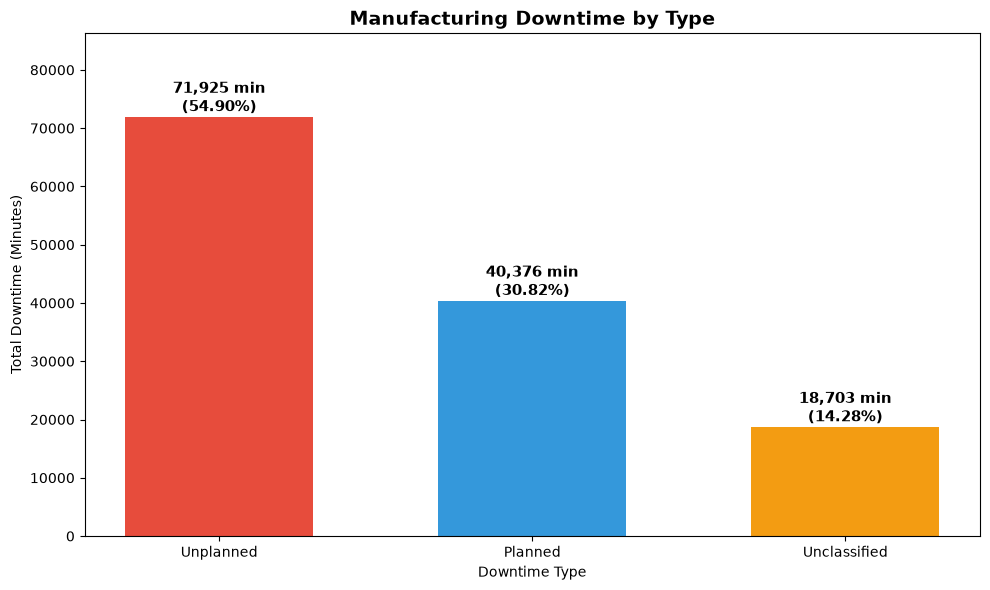

In [38]:
# Step 27: Downtime Type Visualization

import matplotlib.pyplot as plt

# Sort downtime types
type_chart = downtime_type_analysis.sort_values(
    by="Total_Downtime_Min",
    ascending=False
)

# Define colors
colors = {
    "Unplanned": "#e74c3c",
    "Planned": "#3498db",
    "Unclassified": "#f39c12"
}

bar_colors = [
    colors.get(t, "gray")
    for t in type_chart["Downtime_Type"]
]

plt.figure(figsize=(10, 6))

bars = plt.bar(
    type_chart["Downtime_Type"],
    type_chart["Total_Downtime_Min"],
    color=bar_colors,
    width=0.6
)

# Add values and percentages
for bar, percentage in zip(
    bars,
    type_chart["Downtime_Contribution_%"]
):
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 1000,
        f"{height:,.0f} min\n({percentage:.2f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.title(
    "Manufacturing Downtime by Type",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Downtime Type")
plt.ylabel("Total Downtime (Minutes)")

plt.ylim(
    0,
    type_chart["Total_Downtime_Min"].max() * 1.2
)

plt.tight_layout()
plt.show()


In [39]:
# Step 28: Monthly Downtime Trend Analysis

import pandas as pd

# Load cleaned fact table
fact = pd.read_csv(
    "Cleaned_Data/fact_machine_shift.csv"
)

# Convert production date
fact["prod_date"] = pd.to_datetime(
    fact["prod_date"],
    errors="coerce"
)

# Check invalid dates
print("Invalid Dates:", fact["prod_date"].isna().sum())

# Create Year-Month column
fact["Year_Month"] = (
    fact["prod_date"].dt.to_period("M")
)

# Aggregate monthly downtime
monthly_downtime = (
    fact.groupby("Year_Month")
    .agg(
        Total_Downtime_Min=("Downtime_Min", "sum"),
        Total_Planned_Min=("planned_minutes", "sum"),
        Total_Records=("log_id", "count")
    )
    .reset_index()
)

# Calculate downtime rate
monthly_downtime["Downtime_Rate_%"] = (
    monthly_downtime["Total_Downtime_Min"]
    / monthly_downtime["Total_Planned_Min"]
    * 100
).round(2)

# Convert month to string
monthly_downtime["Year_Month"] = (
    monthly_downtime["Year_Month"].astype(str)
)

# Display results
print("MONTHLY DOWNTIME TREND ANALYSIS")
print("-" * 50)

display(monthly_downtime)

# Validate total downtime
print(
    "\nTotal Downtime:",
    monthly_downtime["Total_Downtime_Min"].sum()
)

print(
    "Total Records:",
    monthly_downtime["Total_Records"].sum()
)

Invalid Dates: 0
MONTHLY DOWNTIME TREND ANALYSIS
--------------------------------------------------


,Year_Month,Total_Downtime_Min,Total_Planned_Min,Total_Records,Downtime_Rate_%
0,2026-07,44579,311850,693,14.30
1,2026-08,42577,295650,657,14.40
2,2026-09,43848,299700,666,14.63



Total Downtime: 131004
Total Records: 2016


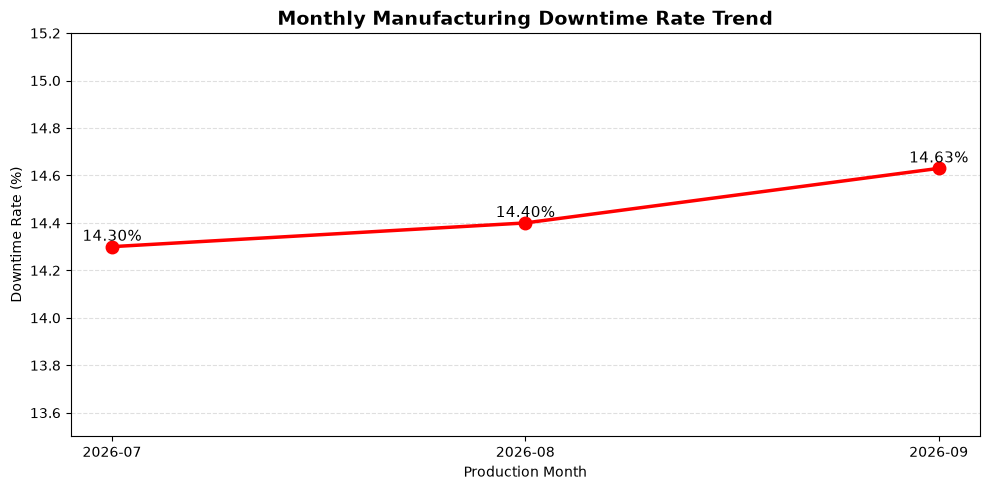

In [40]:
# Step 29: Monthly Downtime Trend Visualization

import matplotlib.pyplot as plt

# Create figure
plt.figure(figsize=(10, 5))

# Plot monthly downtime rate
plt.plot(
    monthly_downtime["Year_Month"],
    monthly_downtime["Downtime_Rate_%"],
    marker="o",
    linewidth=2.5,
    markersize=9,
    color="red"
)

# Add percentage labels
for x, y in zip(
    monthly_downtime["Year_Month"],
    monthly_downtime["Downtime_Rate_%"]
):
    plt.text(
        x,
        y + 0.025,
        f"{y:.2f}%",
        ha="center",
        fontsize=11
    )

# Chart formatting
plt.title(
    "Monthly Manufacturing Downtime Rate Trend",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Production Month")
plt.ylabel("Downtime Rate (%)")

plt.ylim(13.5, 15.2)

plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.4
)

plt.tight_layout()
plt.show()

In [41]:
# Step 30: Machine × Downtime Reason Analysis

import pandas as pd

# Group downtime by machine and reason
machine_reason_analysis = (
    events.groupby(
        ["machine_id", "reason_code"]
    )
    .agg(
        Total_Downtime_Min=("Duration_Min", "sum"),
        Total_Events=("event_id", "count"),
        Avg_Downtime_Min=("Duration_Min", "mean")
    )
    .reset_index()
)

# Round average downtime
machine_reason_analysis["Avg_Downtime_Min"] = (
    machine_reason_analysis["Avg_Downtime_Min"].round(2)
)

# Sort by highest downtime
machine_reason_analysis = (
    machine_reason_analysis.sort_values(
        by="Total_Downtime_Min",
        ascending=False
    )
)

print("MACHINE × DOWNTIME REASON ANALYSIS")
print("-" * 50)

display(machine_reason_analysis.head(20))

# Validate total downtime
print("\nTotal Downtime:",
      machine_reason_analysis["Total_Downtime_Min"].sum())

print("Total Events:",
      machine_reason_analysis["Total_Events"].sum())

MACHINE × DOWNTIME REASON ANALYSIS
--------------------------------------------------


,machine_id,reason_code,Total_Downtime_Min,Total_Events,Avg_Downtime_Min
0,ASM-07,Changeover / Setup,8771,170,51.59
58,CNC-05,Mechanical Breakdown,8413,154,54.63
8,ASM-08,Changeover / Setup,7836,150,52.24
16,ASM-09,Changeover / Setup,7126,138,51.64
42,CNC-03,Mechanical Breakdown,5129,84,61.06
50,CNC-04,Mechanical Breakdown,4735,80,59.19
34,CNC-02,Mechanical Breakdown,4663,75,62.17
10,ASM-08,Mechanical Breakdown,4570,78,58.59
2,ASM-07,Mechanical Breakdown,4390,74,59.32
26,CNC-01,Mechanical Breakdown,4228,70,60.40



Total Downtime: 131004
Total Events: 3240


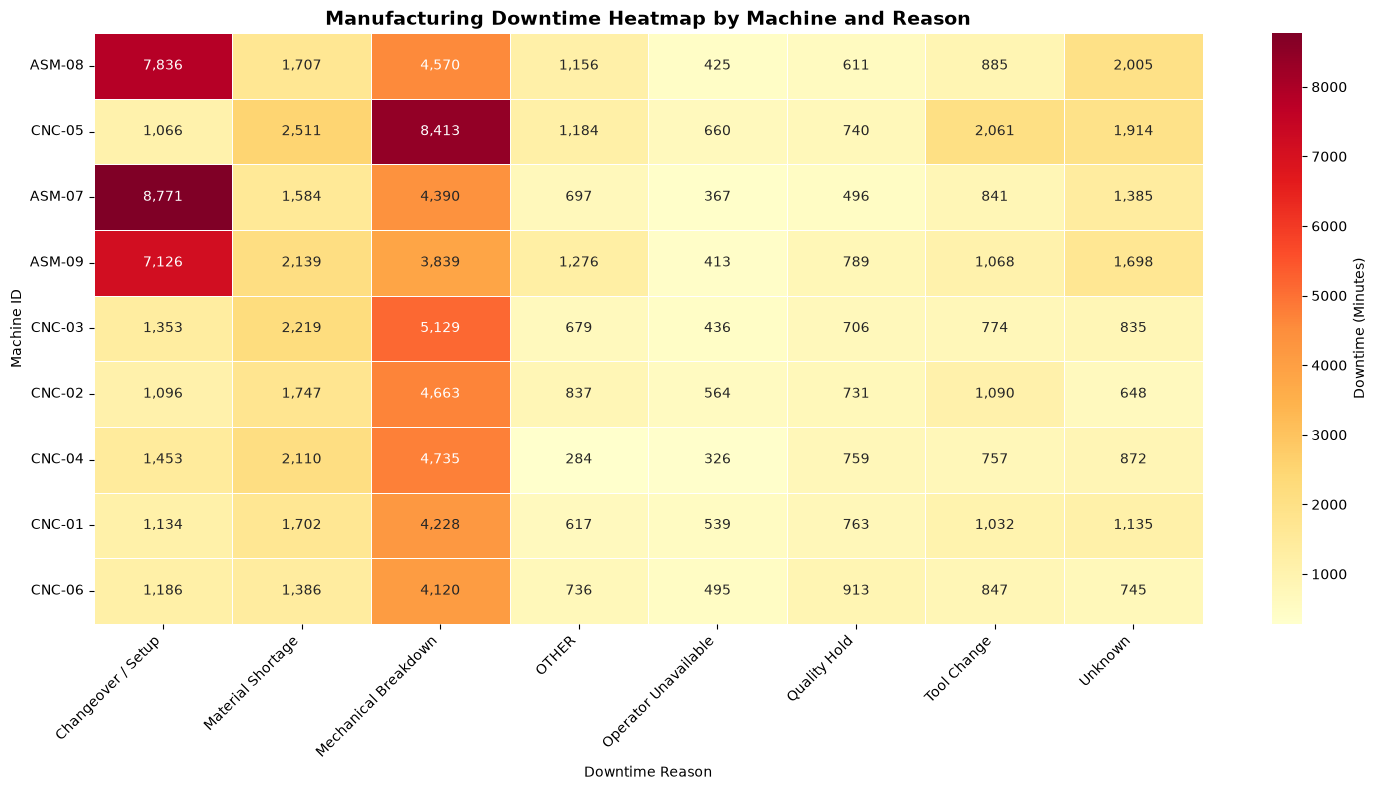

Total Downtime: 131004


In [42]:
# Step 31: Machine × Downtime Reason Heatmap

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Create pivot table
machine_reason_pivot = events.pivot_table(
    index="machine_id",
    columns="reason_code",
    values="Duration_Min",
    aggfunc="sum",
    fill_value=0
)

# Sort machines by total downtime
machine_order = (
    machine_reason_pivot.sum(axis=1)
    .sort_values(ascending=False)
    .index
)

machine_reason_pivot = machine_reason_pivot.loc[machine_order]

# Create heatmap
plt.figure(figsize=(15, 8))

sns.heatmap(
    machine_reason_pivot,
    annot=True,
    fmt=",",
    cmap="YlOrRd",
    linewidths=0.5,
    cbar_kws={"label": "Downtime (Minutes)"}
)

plt.title(
    "Manufacturing Downtime Heatmap by Machine and Reason",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Downtime Reason")
plt.ylabel("Machine ID")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Validate total downtime
print(
    "Total Downtime:",
    machine_reason_pivot.to_numpy().sum()
)

In [43]:
# Step 32: Machine Downtime Contribution Analysis

import pandas as pd

# Group downtime by machine
machine_contribution = (
    events.groupby("machine_id")
    .agg(
        Total_Downtime_Min=("Duration_Min", "sum"),
        Total_Events=("event_id", "count")
    )
    .reset_index()
)

# Calculate contribution percentage
total_downtime = machine_contribution["Total_Downtime_Min"].sum()

machine_contribution["Contribution_%"] = (
    machine_contribution["Total_Downtime_Min"]
    / total_downtime
    * 100
).round(2)

# Sort by highest contribution
machine_contribution = machine_contribution.sort_values(
    by="Total_Downtime_Min",
    ascending=False
).reset_index(drop=True)

# Calculate cumulative contribution
machine_contribution["Cumulative_%"] = (
    machine_contribution["Total_Downtime_Min"].cumsum()
    / total_downtime
    * 100
).round(2)

print("MACHINE DOWNTIME CONTRIBUTION ANALYSIS")
print("-" * 50)

display(machine_contribution)

# Validate results
print("\nTotal Downtime:", total_downtime)

print(
    "Total Events:",
    machine_contribution["Total_Events"].sum()
)

print(
    "Total Contribution:",
    round(machine_contribution["Contribution_%"].sum(), 2),
    "%"
)

MACHINE DOWNTIME CONTRIBUTION ANALYSIS
--------------------------------------------------


,machine_id,Total_Downtime_Min,Total_Events,Contribution_%,Cumulative_%
0,ASM-08,19195,427,14.65,14.65
1,CNC-05,18549,480,14.16,28.81
2,ASM-07,18531,414,14.15,42.96
3,ASM-09,18348,416,14.01,56.96
4,CNC-03,12131,303,9.26,66.22
5,CNC-02,11376,307,8.68,74.91
6,CNC-04,11296,303,8.62,83.53
7,CNC-01,11150,307,8.51,92.04
8,CNC-06,10428,283,7.96,100.00



Total Downtime: 131004
Total Events: 3240
Total Contribution: 100.0 %


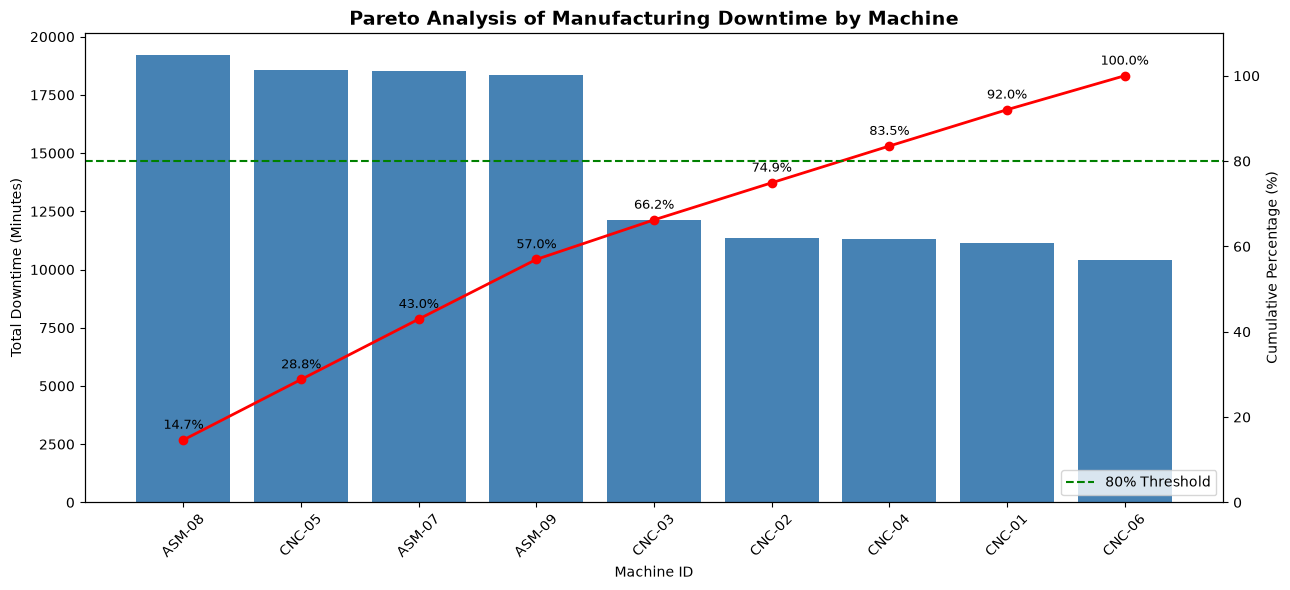

Machines required to reach 80%: 7


In [44]:
# Step 33: Machine Downtime Pareto Analysis

import matplotlib.pyplot as plt

# Use machine contribution data
pareto_machine = machine_contribution.copy()

fig, ax1 = plt.subplots(figsize=(13, 6))

# Downtime bars
ax1.bar(
    pareto_machine["machine_id"],
    pareto_machine["Total_Downtime_Min"],
    color="steelblue"
)

ax1.set_xlabel("Machine ID")
ax1.set_ylabel("Total Downtime (Minutes)")
ax1.set_title(
    "Pareto Analysis of Manufacturing Downtime by Machine",
    fontsize=14,
    fontweight="bold"
)

plt.xticks(rotation=45)

# Secondary axis for cumulative percentage
ax2 = ax1.twinx()

ax2.plot(
    pareto_machine["machine_id"],
    pareto_machine["Cumulative_%"],
    color="red",
    marker="o",
    linewidth=2
)

ax2.set_ylabel("Cumulative Percentage (%)")
ax2.set_ylim(0, 110)

# 80% threshold
ax2.axhline(
    y=80,
    color="green",
    linestyle="--",
    label="80% Threshold"
)

# Percentage labels
for x, y in zip(
    pareto_machine["machine_id"],
    pareto_machine["Cumulative_%"]
):
    ax2.annotate(
        f"{y:.1f}%",
        (x, y),
        textcoords="offset points",
        xytext=(0, 8),
        ha="center",
        fontsize=9
    )

ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

# Identify machines needed to reach 80%
machines_to_80 = (
    (pareto_machine["Cumulative_%"] < 80).sum() + 1
)

print("Machines required to reach 80%:", machines_to_80)

In [45]:
# Step 34: Final Manufacturing Downtime Insights

print("=" * 60)
print("MANUFACTURING DOWNTIME - FINAL BUSINESS INSIGHTS")
print("=" * 60)

# Overall performance
overall_downtime_rate = (
    fact["Downtime_Min"].sum()
    / fact["planned_minutes"].sum()
) * 100

print("\n1. OVERALL PERFORMANCE")
print(f"Total Downtime: {total_downtime:,.0f} minutes")
print(f"Total Events: {len(events):,}")
print(f"Overall Downtime Rate: {overall_downtime_rate:.2f}%")

# Top machines
print("\n2. TOP 4 MACHINES BY DOWNTIME")

display(
    machine_contribution[
        [
            "machine_id",
            "Total_Downtime_Min",
            "Contribution_%"
        ]
    ].head(4)
)

# Top downtime reasons
print("\n3. TOP 3 DOWNTIME REASONS")

display(
    reason_analysis[
        [
            "reason_code",
            "Total_Downtime_Min",
            "Downtime_Contribution_%"
        ]
    ].head(3)
)

# Shift performance
print("\n4. SHIFT PERFORMANCE")

display(
    shift_performance[
        [
            "shift",
            "Downtime_Rate_%"
        ]
    ]
)

# Monthly trend
print("\n5. MONTHLY DOWNTIME TREND")

display(
    monthly_downtime[
        [
            "Year_Month",
            "Downtime_Rate_%"
        ]
    ]
)

print("\n" + "=" * 60)
print("RECOMMENDED ACTIONS")
print("=" * 60)

print("""
1. Prioritize maintenance investigations for machines
   with the highest downtime contribution.

2. Investigate mechanical breakdowns and implement
   preventive maintenance improvements.

3. Review changeover and setup procedures to
   reduce planned downtime.

4. Investigate Shift C performance and identify
   operational bottlenecks.

5. Monitor monthly downtime trends to detect
   performance deterioration.

6. Improve downtime reason classification to
   reduce unknown and unclassified events.
""")

MANUFACTURING DOWNTIME - FINAL BUSINESS INSIGHTS

1. OVERALL PERFORMANCE
Total Downtime: 131,004 minutes
Total Events: 3,240
Overall Downtime Rate: 14.44%

2. TOP 4 MACHINES BY DOWNTIME


,machine_id,Total_Downtime_Min,Contribution_%
0,ASM-08,19195,14.65
1,CNC-05,18549,14.16
2,ASM-07,18531,14.15
3,ASM-09,18348,14.01



3. TOP 3 DOWNTIME REASONS


,reason_code,Total_Downtime_Min,Downtime_Contribution_%
0,Mechanical Breakdown,44087,33.65
1,Changeover / Setup,31021,23.68
2,Material Shortage,17105,13.06



4. SHIFT PERFORMANCE


,shift,Downtime_Rate_%
2,C,16.22
1,B,14.25
0,A,13.14



5. MONTHLY DOWNTIME TREND


,Year_Month,Downtime_Rate_%
0,2026-07,14.30
1,2026-08,14.40
2,2026-09,14.63



RECOMMENDED ACTIONS

1. Prioritize maintenance investigations for machines
   with the highest downtime contribution.

2. Investigate mechanical breakdowns and implement
   preventive maintenance improvements.

3. Review changeover and setup procedures to
   reduce planned downtime.

4. Investigate Shift C performance and identify
   operational bottlenecks.

5. Monitor monthly downtime trends to detect
   performance deterioration.

6. Improve downtime reason classification to
   reduce unknown and unclassified events.



In [46]:
# Step 35: Final Data Validation & Power BI Readiness

import pandas as pd
from pathlib import Path

data_path = Path("Cleaned_Data")

files = [
    "dim_date.csv",
    "dim_shift.csv",
    "downtime_events.csv",
    "fact_machine_shift.csv",
    "machines.csv",
    "products.csv"
]

datasets = {}

print("=" * 60)
print("FINAL DATA VALIDATION & POWER BI READINESS")
print("=" * 60)

# Load datasets
for file in files:

    df = pd.read_csv(data_path / file)

    datasets[file] = df

    print(f"\nDataset: {file}")
    print(f"Rows: {len(df):,}")
    print(f"Columns: {len(df.columns)}")
    print(f"Missing Values: {df.isnull().sum().sum()}")
    print(f"Duplicate Rows: {df.duplicated().sum()}")

# Validate downtime totals
fact_df = datasets["fact_machine_shift.csv"]
events_df = datasets["downtime_events.csv"]

fact_downtime = fact_df["Downtime_Min"].sum()
events_downtime = events_df["Duration_Min"].sum()

print("\n" + "=" * 60)
print("DOWNTIME CONSISTENCY CHECK")
print("=" * 60)

print(f"Fact Table Downtime: {fact_downtime:,.0f}")
print(f"Events Table Downtime: {events_downtime:,.0f}")

if fact_downtime == events_downtime:
    print("Downtime Validation: PASSED")
else:
    print("Downtime Validation: FAILED")

# Check duplicate identifiers
print("\n" + "=" * 60)
print("PRIMARY KEY VALIDATION")
print("=" * 60)

key_checks = {
    "downtime_events.csv": "event_id",
    "machines.csv": "machine_id",
    "products.csv": "product_id"
}

for file, key in key_checks.items():

    df = datasets[file]

    if key in df.columns:

        duplicates = df[key].duplicated().sum()

        print(f"{file} | {key} | Duplicates: {duplicates}")

    else:
        print(f"{file} | Column {key} not found")

print("\nValidation checks completed.")

FINAL DATA VALIDATION & POWER BI READINESS

Dataset: dim_date.csv
Rows: 123
Columns: 10
Missing Values: 0
Duplicate Rows: 0

Dataset: dim_shift.csv
Rows: 3
Columns: 6
Missing Values: 0
Duplicate Rows: 0

Dataset: downtime_events.csv
Rows: 3,240
Columns: 15
Missing Values: 0
Duplicate Rows: 0

Dataset: fact_machine_shift.csv
Rows: 2,016
Columns: 24
Missing Values: 24
Duplicate Rows: 0

Dataset: machines.csv
Rows: 9
Columns: 5
Missing Values: 0
Duplicate Rows: 0

Dataset: products.csv
Rows: 6
Columns: 4
Missing Values: 0
Duplicate Rows: 0

DOWNTIME CONSISTENCY CHECK
Fact Table Downtime: 131,004
Events Table Downtime: 131,004
Downtime Validation: PASSED

PRIMARY KEY VALIDATION
downtime_events.csv | event_id | Duplicates: 0
machines.csv | machine_id | Duplicates: 0
products.csv | product_id | Duplicates: 0

Validation checks completed.


In [47]:
# Step 36: Data Model Relationship Validation

print("=" * 60)
print("POWER BI DATA MODEL VALIDATION")
print("=" * 60)

fact = datasets["fact_machine_shift.csv"]
events = datasets["downtime_events.csv"]
machines = datasets["machines.csv"]
products = datasets["products.csv"]
dates = datasets["dim_date.csv"]
shifts = datasets["dim_shift.csv"]

# Display columns to identify relationship keys
for name, df in [
    ("Fact Table", fact),
    ("Downtime Events", events),
    ("Machines", machines),
    ("Products", products),
    ("Date Dimension", dates),
    ("Shift Dimension", shifts)
]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

print("\n" + "=" * 60)
print("FACT TABLE QUALITY VALIDATION")
print("=" * 60)

print("Fact Rows:", len(fact))
print("Duplicate Rows:", fact.duplicated().sum())
print("Missing Values:", fact.isnull().sum().sum())

if "Quality_Data_Valid" in fact.columns:
    print("\nQuality Status:")
    print(fact["Quality_Data_Valid"].value_counts(dropna=False))

print("\n" + "=" * 60)
print("DOWNTIME CONSISTENCY")
print("=" * 60)

fact_total = fact["Downtime_Min"].sum()
events_total = events["Duration_Min"].sum()

print("Fact Downtime:", fact_total)
print("Events Downtime:", events_total)
print("Difference:", events_total - fact_total)

print(
    "Status:",
    "PASSED" if fact_total == events_total else "FAILED"
)

POWER BI DATA MODEL VALIDATION

Fact Table
Rows: 2016
Columns: ['log_id', 'slot_key', 'prod_date', 'shift', 'machine_id', 'work_order', 'product_id', 'planned_minutes', 'total_units', 'units_imputed', 'Downtime_Events', 'Downtime_Min', 'Planned_Downtime_Min', 'Unplanned_Downtime_Min', 'Unclassified_Downtime_Min', 'Rejected_Units', 'Invalid_Reject_Count', 'primary_defect', 'Run_Time_Min', 'Ideal_Units', 'Quality_Basis_Units', 'Good_Units', 'Scrap_Cost_USD', 'Quality_Data_Valid']

Downtime Events
Rows: 3240
Columns: ['event_id', 'slot_key', 'machine_id', 'event_date', 'shift', 'Start_Date', 'Start_Time', 'End_Date', 'End_Time', 'Start_Hour', 'Duration_Min', 'reason_code', 'Downtime_Type', 'operator_note', 'Time_Swapped']

Machines
Rows: 9
Columns: ['machine_id', 'machine_name', 'line', 'machine_type', 'ideal_cycle_time_sec']

Products
Rows: 6
Columns: ['product_id', 'product_name', 'product_family', 'unit_cost_usd']

Date Dimension
Rows: 123
Columns: ['Date', 'Year', 'Month_Num', 'Month_

In [48]:
# Step 37: Foreign Key & Relationship Validation

import pandas as pd

fact = datasets["fact_machine_shift.csv"]
events = datasets["downtime_events.csv"]
machines = datasets["machines.csv"]
products = datasets["products.csv"]
dates = datasets["dim_date.csv"]
shifts = datasets["dim_shift.csv"]

print("=" * 60)
print("POWER BI RELATIONSHIP VALIDATION")
print("=" * 60)


def validate_relationship(
    child,
    parent,
    child_key,
    parent_key,
    relationship_name
):

    print(f"\n{relationship_name}")

    if child_key not in child.columns:
        print(f"FAILED: Missing child column {child_key}")
        return

    if parent_key not in parent.columns:
        print(f"FAILED: Missing parent column {parent_key}")
        return

    child_values = child[child_key].dropna()

    parent_values = parent[parent_key].dropna()

    missing = ~child_values.isin(parent_values)

    unmatched = missing.sum()

    parent_duplicates = parent[parent_key].duplicated().sum()

    child_nulls = child[child_key].isna().sum()

    parent_nulls = parent[parent_key].isna().sum()

    print("Unmatched Foreign Keys:", unmatched)
    print("Parent Key Duplicates:", parent_duplicates)
    print("Child Null Keys:", child_nulls)
    print("Parent Null Keys:", parent_nulls)

    if (
        unmatched == 0
        and parent_duplicates == 0
        and child_nulls == 0
        and parent_nulls == 0
    ):
        print("Status: PASSED")
    else:
        print("Status: NEEDS INVESTIGATION")


# Machine relationship
validate_relationship(
    fact,
    machines,
    "machine_id",
    "machine_id",
    "Fact → Machines"
)

# Product relationship
validate_relationship(
    fact,
    products,
    "product_id",
    "product_id",
    "Fact → Products"
)

# Date relationship
validate_relationship(
    fact,
    dates,
    "prod_date",
    "Date",
    "Fact → Date"
)

# Events machine relationship
validate_relationship(
    events,
    machines,
    "machine_id",
    "machine_id",
    "Events → Machines"
)

# Events date relationship
validate_relationship(
    events,
    dates,
    "event_date",
    "Date",
    "Events → Date"
)

# Slot key validation
print("\n" + "=" * 60)
print("SLOT KEY VALIDATION")
print("=" * 60)

print(
    "Fact Duplicate Slot Keys:",
    fact["slot_key"].duplicated().sum()
)

print(
    "Events Unmatched Slot Keys:",
    (~events["slot_key"].isin(fact["slot_key"])).sum()
)

print("\nRelationship validation completed.")

POWER BI RELATIONSHIP VALIDATION

Fact → Machines
Unmatched Foreign Keys: 0
Parent Key Duplicates: 0
Child Null Keys: 0
Parent Null Keys: 0
Status: PASSED

Fact → Products
Unmatched Foreign Keys: 0
Parent Key Duplicates: 0
Child Null Keys: 0
Parent Null Keys: 0
Status: PASSED

Fact → Date
Unmatched Foreign Keys: 0
Parent Key Duplicates: 0
Child Null Keys: 0
Parent Null Keys: 0
Status: PASSED

Events → Machines
Unmatched Foreign Keys: 0
Parent Key Duplicates: 0
Child Null Keys: 0
Parent Null Keys: 0
Status: PASSED

Events → Date
Unmatched Foreign Keys: 0
Parent Key Duplicates: 0
Child Null Keys: 0
Parent Null Keys: 0
Status: PASSED

SLOT KEY VALIDATION
Fact Duplicate Slot Keys: 0
Events Unmatched Slot Keys: 0

Relationship validation completed.


In [49]:
# Step 38: Final Power BI Relationship Checks

print("=" * 60)
print("FINAL POWER BI MODEL CHECKS")
print("=" * 60)

# Check Shift Dimension
print("\nSHIFT DIMENSION COLUMNS")
print(shifts.columns.tolist())

# Check Fact and Events shift values
print("\nFACT SHIFTS")
print(fact["shift"].value_counts())

print("\nEVENT SHIFTS")
print(events["shift"].value_counts())

# Check slot_key relationship
print("\nSLOT KEY RELATIONSHIP")

print(
    "Fact Unique Slot Keys:",
    fact["slot_key"].nunique()
)

print(
    "Fact Total Rows:",
    len(fact)
)

print(
    "Events Unique Slot Keys:",
    events["slot_key"].nunique()
)

print(
    "Events Total Rows:",
    len(events)
)

# Check events per slot
events_per_slot = (
    events.groupby("slot_key")
    .size()
)

print("\nEVENTS PER SLOT")

print(events_per_slot.describe())

# Validate shift consistency between fact and events
slot_shift = fact[["slot_key", "shift"]].rename(
    columns={"shift": "fact_shift"}
)

events_check = events[
    ["slot_key", "shift"]
].merge(
    slot_shift,
    on="slot_key",
    how="left",
    validate="many_to_one"
)

shift_mismatches = (
    events_check["shift"]
    != events_check["fact_shift"]
).sum()

print("\nSHIFT CONSISTENCY")
print("Shift Mismatches:", shift_mismatches)

print("\n" + "=" * 60)
print("MODEL PREPARATION COMPLETED")
print("=" * 60)

FINAL POWER BI MODEL CHECKS

SHIFT DIMENSION COLUMNS
['shift', 'shift_name', 'shift_order', 'start_hour', 'end_hour', 'shift_hours']

FACT SHIFTS
shift
A    711
B    711
C    594
Name: count, dtype: int64

EVENT SHIFTS
shift
B    1111
C    1075
A    1054
Name: count, dtype: int64

SLOT KEY RELATIONSHIP
Fact Unique Slot Keys: 2016
Fact Total Rows: 2016
Events Unique Slot Keys: 1594
Events Total Rows: 3240

EVENTS PER SLOT
count    1594.000000
mean        2.032622
std         1.085863
min         1.000000
25%         1.000000
50%         2.000000
75%         3.000000
max         5.000000
dtype: float64

SHIFT CONSISTENCY
Shift Mismatches: 0

MODEL PREPARATION COMPLETED


In [ ]:
ٍ